# Example on How to Overplot Cluster Locations
- Showingboth Methods 1. Manual and 2. CARTA regions
-  Author: @aelieber1, @millbets

## Import Packages

In [179]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

from astropy.wcs import WCS
from astropy import units as u
from astropy.wcs.utils import proj_plane_pixel_scales
from astropy.visualization.wcsaxes import add_beam, add_scalebar

from spectral_cube import SpectralCube

import astropy.io.fits as fits

# Plot formatting
%matplotlib inline
matplotlib.rc('font', family='sans-serif')
matplotlib.rc('text', usetex=False)

In [91]:
# Import your data (I'll use a cube here and make a mom0 map)

#H40alpha_processed_path = '/Users/ashleylieber/MIlls_Research/VibCubes/UniformProcessing_Feb2024/Smoothed_DataCubes/H40_Alpha_smoothed.fits'
#H40alpha_processed_cube = SpectralCube.read(H40alpha_processed_path)

#filelabel = "H40_Alpha" # How the file is labeled in my directory
#fmt_label = "H40 $a$" # Nicely formated label 

#moment0 = H40alpha_processed_cube.moment(order=0, how='slice')

# This gives us a nice 2D image (similar to how a continuum image already is)
# you might not be able to import a readymade continuum file into SpectralCube (it can yell at you when it isn't 3D), so if that is the case, you can import using fits (example below)
#cont = fits.getdata(__path__)
#ont_header = fits.getheader(dataset_dpathir)

## Method 1: Manually Input Cluster Locations and Plot

In [28]:
# Get the pixel location of our apertures
w_ref = moment0.wcs # Grab the 2D coordinate system from the moment map
# w_ref = WCS.dropaxis(w_ref, dropax=2) # if your continuum has a 3rd axis you might need to drop it
# print(w_ref) # you can check the structure by printing

xs = np.zeros((14),float) # will eventaully store the pixel locations of x coordiantes of each SSC
ys = np.zeros((14),float) # will eventaully store the pixel locations of y coordiantes of each SSC

# Locations of SSCs in NGC 253
sources = np.array(['1','2','3','4','5','6','7','8','9','10','11','12','13','14'])

# Source Right Ascensions (Mills+2021)
RAs =  np.array([11.886669,11.886749,11.886829,11.8872162,11.8874364,11.88755,\
                    11.887567,11.887978,11.887984,11.8881464,\
                    11.8882,11.888264,11.888322,11.8887287])

# Source Declinations (Mills+2021)
Decs = np.array([-25.289232,-25.289240,-25.289200,-25.2889692,-25.288806,-25.288737,\
                    -25.288628,-25.288244,-25.288389,-25.2880799,\
                    -25.288175,-25.288095,-25.287989,-25.2876482]) 

# Convert all RA and DECs to pixels
for i in np.arange(0,14):
    xs[i],ys[i] = w_ref.all_world2pix(RAs[i],Decs[i],0)

In [29]:
# In Mills+2021 and Lieber et al. (in prep) the apertures have 3pc radii, we need to calculate this in pixels
D = 3.5e6 * u.pc # Dist to NGC 253
aperture_radius = 3.0 * u.pc 

theta = (aperture_radius/D * u.rad).to(u.arcsec) # radius in angular size (Linear to angular size equation)
print(f"Angular radius: {theta:.3f}") # Radius in angular units

pixscale = abs(H40alpha_processed_cube.header['CDELT1']) * u.deg # you can grab the size of the pixel from the header; CDELT2 should be the same 
print(f"Pixel scale: {pixscale.to(u.arcsec):.2f}") # How big are our pixels 

apsize = (theta / pixscale.to(u.arcsec)).value # Calculates how many pixels you need to have a radius at the proper radius you set
print(f"Aperture radius: {apsize:.3f} pixels") 



Angular radius: 0.177 arcsec
Pixel scale: 0.03 arcsec
Aperture radius: 5.893 pixels


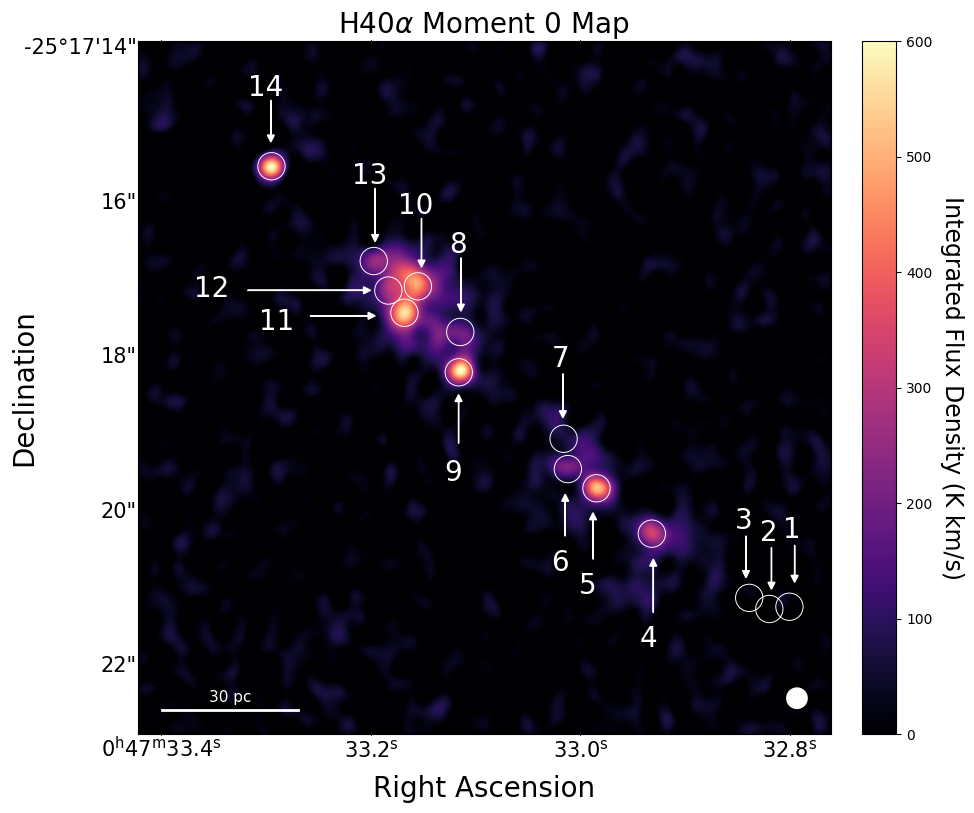

In [30]:

# Location information for arrows (if you wnat to have numbers and arrows) -- if you just want the circles, disregard
Lx  = np.array([283,273,262,222,196,184,183,139,  138,122,74,  47,102, 57])
Ly  = np.array([ 81, 80, 85, 52, 75, 85,155,205,  125,222,180, 191,235,273])
Ldx = np.array([  0,  0,  0,  0,  0,  0,  0,  0,    0,  0,  25,  50,  0,  0])
Ldy = np.array([-13,-15,-15, 20, 17, 15,-16,-20,   18, -18,  0,   0,-20,-15])
Ltx = np.array([ -5, -5, -5, -6, -6, -6, -5, -5,   -6, -10, -22, -23, -10, -10])
Lty = np.array([  3,  3,  3,-15,-15,-15,  3,  2,    -16, 2,  -6,-3,  2,  2])

# Plotting
fig = plt.figure(1,figsize=(10,9))

ax = plt.subplot(1,1,1,projection=moment0.wcs) 
im = ax.imshow(moment0.hdu.data,cmap='magma',origin='lower',vmin=0,vmax=600)

ax.set_title(r'H40$\alpha$ Moment 0 Map', fontsize=20)

RA = ax.coords[0]                                                                  
Dec = ax.coords[1]
RA.set_ticks(size=1)                                                                                      
Dec.set_ticks(size=-3)     

plt.xlabel('Right Ascension',fontsize=20,labelpad=1)                               
plt.ylabel('Declination',fontsize=20,labelpad=0)

ax.tick_params(axis = 'both', which = 'major', labelsize = 15)  
 
cb = fig.colorbar(im, ax=ax, fraction=0.046,pad=0.04)                                      
cb.set_label(label='Integrated Flux Density (K km/s)',fontsize=17,rotation=270,labelpad=23) 
cb.ax.tick_params(which = 'major', labelsize = 10) 

########################### this is the aperture plotting that is important!! ###########################

for i,x in enumerate(xs):
    ax.add_patch(matplotlib.patches.Circle((x,ys[i]),apsize,fill=False,lw=0.7,edgecolor='white',zorder=5)) #uses the apsize you defined to set the radius


############################################################################################################

for i,x in enumerate(Lx):
    ax.arrow(x,Ly[i], Ldx[i], Ldy[i],width=0.1,head_width=3,head_length=3,color='white')
    ax.text(x+Ltx[i],Ly[i]+Lty[i],sources[i],fontsize=20,color='white')

############################################################################################################

# Add 30 pc scale bar
D = 3.5e6 * u.pc
L = 30 * u.pc
theta = (L / D) * u.rad
theta_arcsec = theta.to(u.arcsec)
pixscale = abs(H40alpha_processed_cube.header['CDELT1']) * u.deg
bar_length_pix = (theta_arcsec / pixscale.to(u.arcsec)).value
ax.plot([10, 10 + bar_length_pix],[10, 10],color='white',lw=2)
ax.text(10 + bar_length_pix / 2,12,"30 pc",color='white',ha='center',va='bottom',fontsize=11)

# Add Beam
beam_radius_pix = (H40alpha_processed_cube.header['BMAJ'] / abs(H40alpha_processed_cube.header['CDELT1'])) / 2.0
ny, nx = moment0.shape
beam_x = nx - 15
beam_y = 15
ax.add_patch(matplotlib.patches.Circle((beam_x, beam_y),beam_radius_pix,fill=True,lw=1.2,fc='white',ec='white')) 

plt.show()


## Method 2: CARTA Region File

In [431]:
# You'll need this package
import regions
from regions import Regions
from regions import PixCoord
from regions import RectangleSkyRegion, RectanglePixelRegion

import pylab

# Load the CARTA region file
region_path = "/Users/mills-group/Downloads/regions-notebook/H40a_region"
H40a_region = Regions.read(region_path, format="crtf")
print(f"Loaded {len(H40a_crop)} aperture")

H40a_path = '/Users/mills-group/Downloads/regions-notebook/NGC253_H40a_2016.1.00481.c.S.fits'
H40a_cube = SpectralCube.read(H40a_path)

filelabel = "NGC253_H40a"
fmt_label = "H40 $a$"

H40a_crop = H40a_cube.subcube_from_regions(H40a_region)
H40a_crop.hdu.writeto('NGC253_H40a_2016.1.00481.c.S.fits', overwrite=True)

H40a_crop_cube = SpectralCube.read(H40a_path)

moment0 = H40a_crop_cube.moment(order=0, how='slice')
imgshape = np.shape(moment0)
print(imgshape)
#region_H40a = RectanglePixelRegion(center=PixCoord(x=1270,y=1287),width=300,height=264, angle=0*u.deg)
#crop_H40a = H40a_cube.subcube_from_regions(region_H40a)


Loaded 41 aperture
(265, 300)


## Band 3 vs. Band 7 (1-7)

In [433]:
def fake_cube(imagename, extension):
    data = fits.getdata(imagename+extension)
    data_new = data[np.newaxis,:,:]
    header = fits.getheader(imagename+extension)
    header["NAXIS"] = 3
    header["NAXIS3"] = 1
    header["CRPIX3"] = 1.000000000000E+00
    header["CTYPE3"] = 'FREQ    '
    header["CUNIT3"] = 'Hz      '
    #header["CRVAL3"] = header['RESTFRQ']
    header["CDELT3"] = 1.000000000000E+00

    newfile = fits.writeto(imagename+"fake_cube"+extension,data_new,header,overwrite=True)

In [445]:
#imagename3 = 'NGC253_Band3_continuum_2_5pc.c'
#ext = '.fits'
#rest_freq3 = header['RESTFRQ']
#fake_cube(imagename3, ext,rest_freq3)
#for a file imagename.fits
#image = "imagename"
#ext= ".fits"
#fake_cube(image, ext, freq)

#cont3_cube_path = '/Users/mills-group/Downloads/regions-notebook/NGC253_Band3_continuum_2_5pc.cfake_cube.fits'
cont3_cube_path = '/Users/mills-group/Downloads/regions-notebook/NGC253_Band3_continuum_2_5pc.c.fits'
image3 = fits.getdata(cont3_cube_path)
header3 = fits.getheader(cont3_cube_path)
w3 = WCS(header3)
w3 = w3.dropaxis(2)
#region_cont_path = "/Users/mills-group/Downloads/regions-notebook/cont_region_world"
crop_region_cont_path = "/Users/mills-group/Downloads/regions-notebook/1-7_region"
#region_str = "ellipse[[00:47:33.08850, -025.17.18.4021], [4.5506arcsec, 10.8365arcsec], 50.57983398deg], coord=fk5" 
#region = regions.Regions.parse(region_str,format='crtf')
print(np.shape(image3))
#print(header3)

cont3_region = Regions.read(crop_region_cont_path, format='crtf')
image3 = pylab.squeeze(image3)
print(np.shape(image3))
#im3 = pylab.imshow(image3,cmap='magma')
cont3_cube = SpectralCube.read(cont3_cube_path)
#cont3_cube = pylab.squeeze(cont3_cube)
print(np.shape(image3))


region = regions.Regions.parse(region_str,format='crtf')
crop_cont3_cube = cont3_cube.subcube_from_regions(cont3_region)

moment03 = crop_cont3_cube.moment(order=0, how='slice')
#-------------
imagename7 = 'ngc253_Band7_dust'
ext = '.fits'
#rest_freq3 = header['RESTFRQ']
cont7_fake = fake_cube(imagename7, ext)
cont7_cube_path = '/Users/mills-group/Downloads/regions-notebook/ngc253_Band7_dustfake_cube.fits'
image7 = fits.getdata(cont7_cube_path)
header7 = fits.getheader(cont7_cube_path)
w7 = WCS(header7)
#w7 = w7.dropaxis(2)
#region_cont_path = "/Users/mills-group/Downloads/regions-notebook/cont_region_world"
crop_region_cont_path = "/Users/mills-group/Downloads/regions-notebook/1-7_region"
#region_str = "ellipse[[00:47:33.08850, -025.17.18.4021], [4.5506arcsec, 10.8365arcsec], 50.57983398deg], coord=fk5" 
#region = regions.Regions.parse(region_str,format='crtf')
print(np.shape(image7))
#print(header3)

cont7_region = Regions.read(crop_region_cont_path, format='crtf')
image7 = pylab.squeeze(image7)
print(np.shape(image7))
cont7_cube = SpectralCube.read(cont7_cube_path)
#cont3_cube = pylab.squeeze(cont3_cube)
print(np.shape(image7))


#region = regions.Regions.parse(region_str,format='crtf')
crop_cont7_cube = cont7_cube.subcube_from_regions(cont7_region)

moment07 = crop_cont7_cube.moment(order=0, how='slice')
#im3 = pylab.imshow(moment03.data,cmap='magma')
#pylab.show()

(1, 1, 1920, 1920)
(1920, 1920)


(1920, 1920)


(1, 1500, 2500)


(1500, 2500)
(1500, 2500)


WCS Keywords

Number of WCS axes: 3
CTYPE : 'RA---SIN' 'DEC--SIN' 'STOKES' 
CRVAL : 11.88834416667 -25.28801916667 1.0 
CRPIX : 961.0 961.0 1.0 
PC1_1 PC1_2 PC1_3  : 1.0 0.0 0.0 
PC2_1 PC2_2 PC2_3  : 0.0 1.0 0.0 
PC3_1 PC3_2 PC3_3  : 0.0 0.0 1.0 
CDELT : -8.333333333333e-06 8.333333333333e-06 1.0 
NAXIS : 1920  1920  1


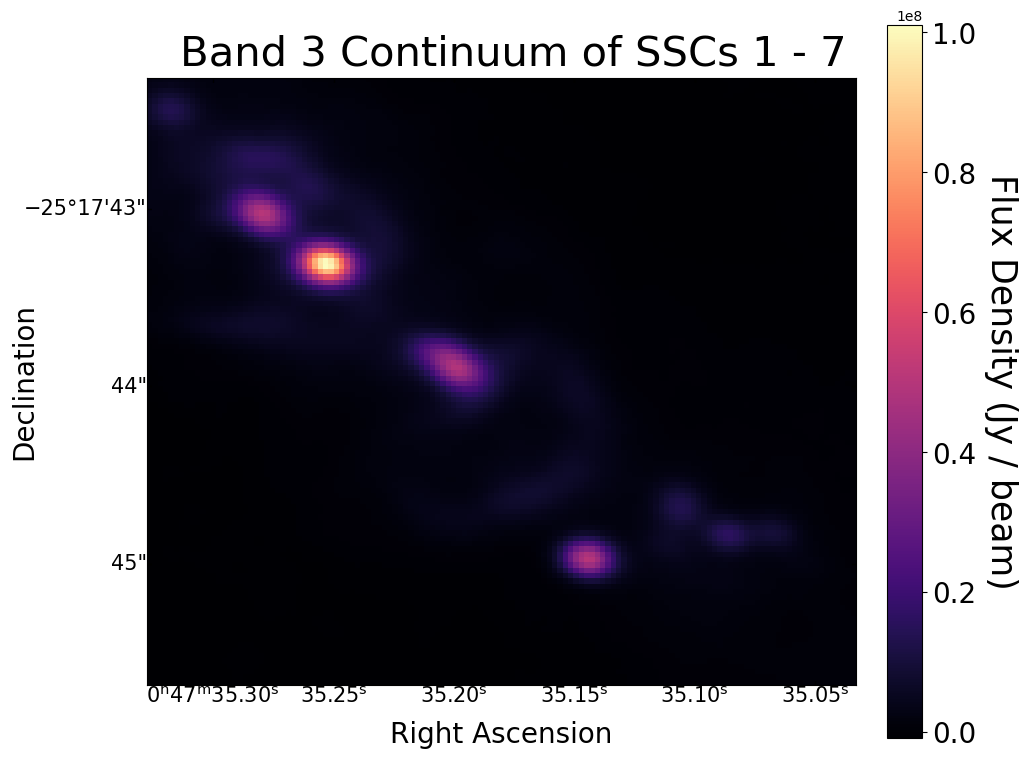

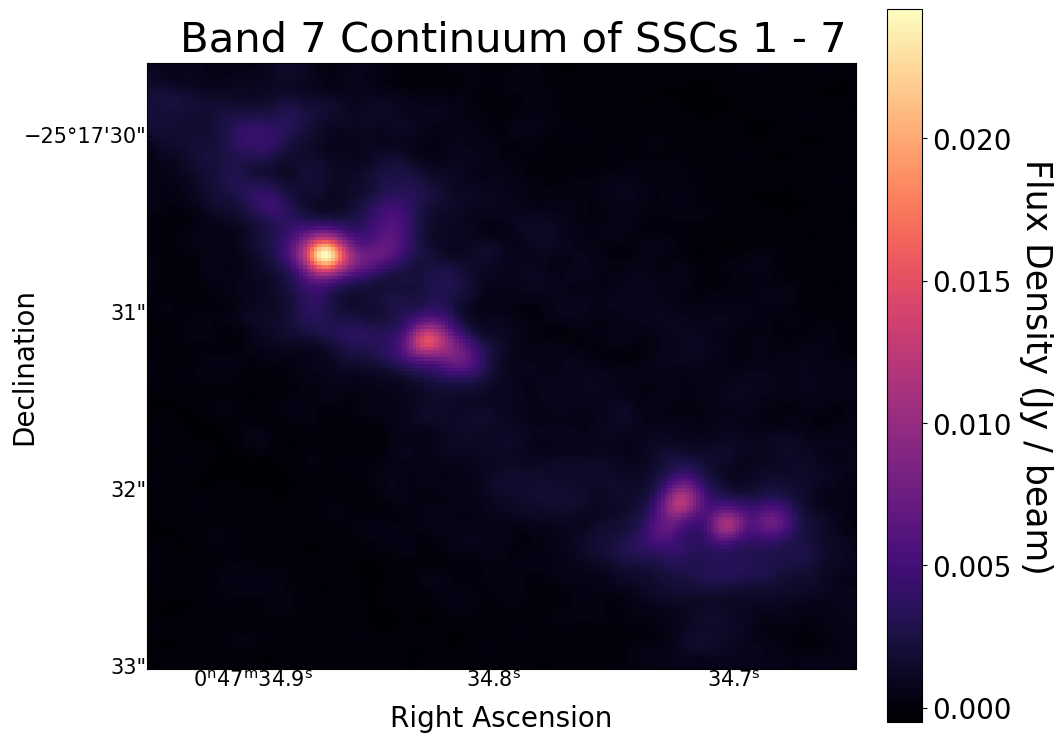

In [446]:
print(w3)
w3 = w3.dropaxis(2)
fig1 = pylab.figure(1,figsize=(10,10))       # We will make this figure #1 and give it a size of 10x10                                             
                                             # We also want to make sure that our image is plotted with sky coordinates
ax1 = pylab.subplot(projection=w3)            # We do this by specifying a projection (the wcs from the previous cell)
RA = ax1.coords[0]
Dec = ax1.coords[1]

im3 = pylab.imshow(moment03.data,cmap='magma')

RA.set_ticks(size=-3)                       # Change the length of the tick marks 
Dec.set_ticks(size=-3)                      # (negative values place ticks inside the bounding box)
pylab.xlabel('Right Ascension',fontsize=20,labelpad=1) # Label the x-axis
pylab.ylabel('Declination',fontsize=20,labelpad=0) # Label the y-axis
ax1.tick_params(axis = 'both', which = 'major', labelsize = 15) # Increase the font of the tick labels
pylab.annotate('Band 3 Continuum of SSCs 1 - 7',fontsize=30,xy=(0.046,1.02),xycoords="axes fraction") # Add a label in the figure
cb=pylab.colorbar(im3,fraction=0.046,pad=0.04) # Define a color bar
cb.set_label(label='Flux Density (Jy / beam)',fontsize=25,rotation=270,labelpad=30) # Add a colorbar label
cb.ax.tick_params(which = 'major', labelsize = 20) # Increase the font size on the colorbar tick labels
###
w7 = w7.dropaxis(2)
fig2 = pylab.figure(2,figsize=(10,10))       # We will make this figure #1 and give it a size of 10x10                                             
                                             # We also want to make sure that our image is plotted with sky coordinates
ax2 = pylab.subplot(projection=w7)            # We do this by specifying a projection (the wcs from the previous cell)
RA = ax2.coords[0]
Dec = ax2.coords[1]

im7 = pylab.imshow(moment07.data,cmap='magma')

RA.set_ticks(size=-3)                       # Change the length of the tick marks 
Dec.set_ticks(size=-3)                      # (negative values place ticks inside the bounding box)
pylab.xlabel('Right Ascension',fontsize=20,labelpad=1) # Label the x-axis
pylab.ylabel('Declination',fontsize=20,labelpad=0) # Label the y-axis
ax2.tick_params(axis = 'both', which = 'major', labelsize = 15) # Increase the font of the tick labels
pylab.annotate('Band 7 Continuum of SSCs 1 - 7',fontsize=30,xy=(0.046,1.02),xycoords="axes fraction") # Add a label in the figure
#ax.set_title(r'H40$\alpha$ Moment 0 Map', fontsize=20)
cb=pylab.colorbar(im7,fraction=0.046,pad=0.04) # Define a color bar
cb.set_label(label='Flux Density (Jy / beam)',fontsize=25,rotation=270,labelpad=30) # Add a colorbar label
cb.ax.tick_params(which = 'major', labelsize = 20) # Increase the font size on the colorbar tick labels

pylab.savefig('Continuum_Comparisons')
pylab.show()


In [177]:
image = fits.getdata(H40a_path)
header = fits.getheader(H40a_path)
mJy_image = image *1000
header['BUNIT'] = 'mJy/beam'
w1 = WCS(header)
#w1 = w1.dropaxis(3)
w1 = w1.dropaxis(2)
image_2d = pylab.squeeze(image)
ra, dec = w1.all_pix2world(1285,1277,0)
print(ra,dec)

region_str = "circle[[11.87475deg, -25.27619deg], 0.8deg], coord=fk5" 
region = regions.Regions.parse(region_str,format='crtf')
crop = H40a_cube.subcube_from_regions(region) 
moment0 = crop.moment(order=0, how='slice')

11.87475229261722 -25.276191084204182


In [443]:
# You'll need this package
from regions import Regions

import pylab

# Load the CARTA region file
region_path = "/Users/mills-group/Downloads/regions-notebook/SSC_Location_Mills2021_3pc.crtf"
apertures = Regions.read(region_path, format="crtf")
print(f"Loaded {len(apertures)} apertures")

Loaded 14 apertures


/var/folders/l3/rs44gkbx5wddf_fykpz4jr1c0000gp/T/ipykernel_37369/1303577960.py:41: UserWarning: Adding colorbar to a different Figure <Figure size 1000x2000 with 2 Axes> than <Figure size 1000x900 with 33 Axes> which fig.colorbar is called on.
  cb = fig.colorbar(im1, ax=ax1, fraction=0.046,pad=0.04)
/var/folders/l3/rs44gkbx5wddf_fykpz4jr1c0000gp/T/ipykernel_37369/1303577960.py:75: UserWarning: Adding colorbar to a different Figure <Figure size 1000x2000 with 2 Axes> than <Figure size 1000x900 with 33 Axes> which fig.colorbar is called on.
  cb = fig.colorbar(im2, ax=ax2, fraction=0.046,pad=0.04)


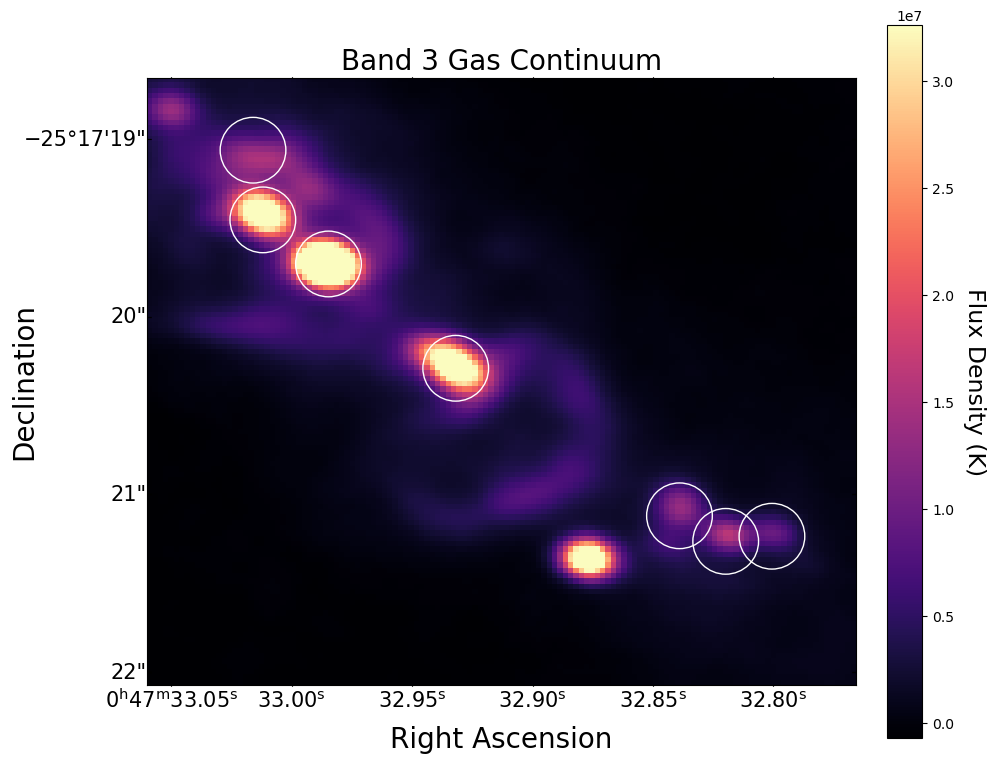

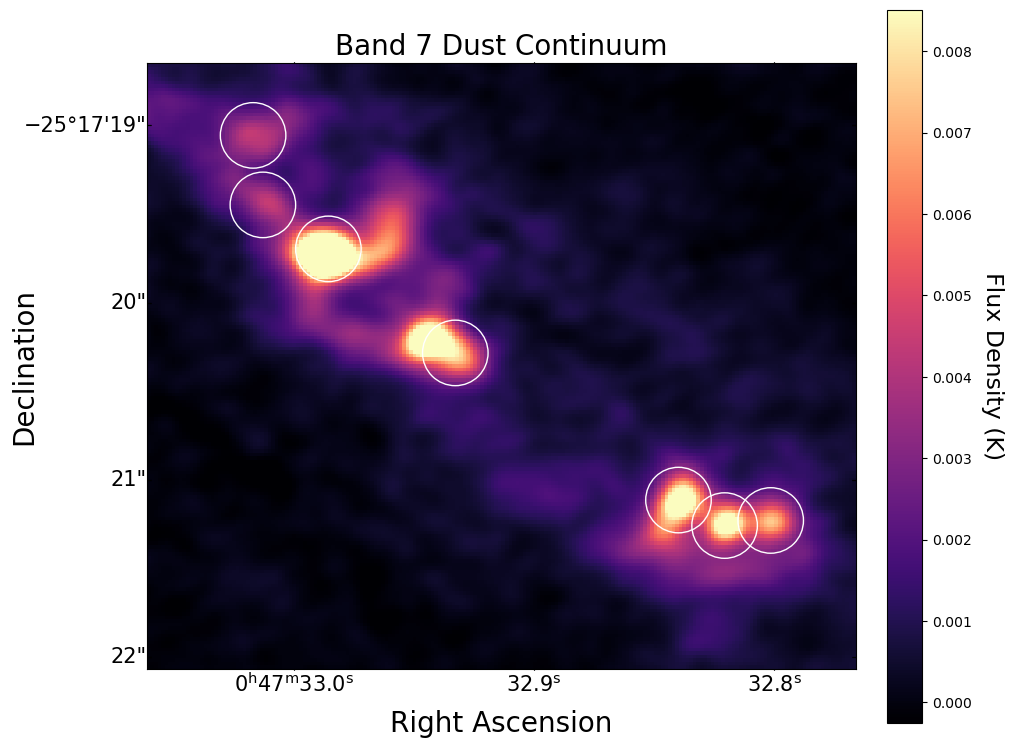

In [447]:
# Location information for arrows (if you wnat to have numbers and arrows) -- if you just want the circles, disregard
#Lx  = np.array([283,273,262,222,196,184,183,139,  138,122,74,  47,102, 57])
#Ly  = np.array([ 81, 80, 85, 52, 75, 85,155,205,  125,222,180, 191,235,273])
#Ldx = np.array([  0,  0,  0,  0,  0,  0,  0,  0,    0,  0,  25,  50,  0,  0])
#Ldy = np.array([-13,-15,-15, 20, 17, 15,-16,-20,   18, -18,  0,   0,-20,-15])
#Ltx = np.array([ -5, -5, -5, -6, -6, -6, -5, -5,   -6, -10, -22, -23, -10, -10])
#Lty = np.array([  3,  3,  3,-15,-15,-15,  3,  2,    -16, 2,  -6,-3,  2,  2])

Lx  = np.array([283,273,262,222,196,184])
Ly  = np.array([ 81, 80, 85, 52, 75, 85])
Ldx = np.array([  0,  0,  0,  0,  0,  0])
Ldy = np.array([-13,-15,-15, 20, 17, 15])
Ltx = np.array([ -5, -5, -5, -6, -6, -6])
Lty = np.array([  3,  3,  3,-15,-15,-15])

# Locations of SSCs in NGC 253
#sources = np.array(['1','2','3','4','5','6','7','8','9','10','11','12','13','14'])
sources = np.array(['1','2','3','4','5','6'])


# Plotting
data_min = np.nanpercentile(moment03.hdu.data, 1)
data_max = np.nanpercentile(moment03.hdu.data, 99)

fig1 = plt.figure(1,figsize=(10,20))

ax1 = plt.subplot(projection=moment03.wcs) 
im1 = ax1.imshow(moment03.hdu.data,cmap='magma',origin='lower',vmin=data_min,vmax=data_max)
ax1.set_title(r'Band 3 Gas Continuum', fontsize=20)

RA1 = ax1.coords[0]                                                                  
Dec1 = ax1.coords[1]
RA1.set_ticks(size=1)                                                                                      
Dec1.set_ticks(size=-3)     

plt.xlabel('Right Ascension',fontsize=20,labelpad=1)                               
plt.ylabel('Declination',fontsize=20,labelpad=0)

ax1.tick_params(axis = 'both', which = 'major', labelsize = 15)  
 
cb = fig.colorbar(im1, ax=ax1, fraction=0.046,pad=0.04)                                      
cb.set_label(label='Flux Density (K)',fontsize=17,rotation=270,labelpad=23) 
cb.ax.tick_params(which = 'major', labelsize = 10) 

for ap in apertures:
    pixel_aperture = ap.to_pixel(moment03.wcs) # convert the CARTA RA/DEC to image pixels
    pixel_aperture.visual = {} # you need this to ignore any of the visual settings that would otherwise give you an error (i.e. symsize) as Matplotlib draws the circle
    pixel_aperture.plot(ax=ax1, edgecolor='white',linewidth=1, fill=False) # Adds the circle to our plot

#for i,x in enumerate(Lx):
#    ax1.arrow(x,Ly[i], Ldx[i], Ldy[i],width=0.1,head_width=3,head_length=3,color='black')
#    ax1.text(x+Ltx[i],Ly[i]+Lty[i],sources[i],fontsize=20,color='black')

#-----------
data_min = np.nanpercentile(moment07.hdu.data, 1)
data_max = np.nanpercentile(moment07.hdu.data, 99)

fig2 = plt.figure(2,figsize=(10,20))

ax2 = plt.subplot(projection=moment07.wcs) 
im2 = ax2.imshow(moment07.hdu.data,cmap='magma',origin='lower',vmin=data_min,vmax=data_max)

ax2.set_title(r'Band 7 Dust Continuum', fontsize=20)

RA = ax2.coords[0]                                                                  
Dec = ax2.coords[1]
RA.set_ticks(size=1)                                                                                      
Dec.set_ticks(size=-3)     

plt.xlabel('Right Ascension',fontsize=20,labelpad=1)                               
plt.ylabel('Declination',fontsize=20,labelpad=0)

ax2.tick_params(axis = 'both', which = 'major', labelsize = 15)  
 
cb = fig.colorbar(im2, ax=ax2, fraction=0.046,pad=0.04)                                      
cb.set_label(label='Flux Density (K)',fontsize=17,rotation=270,labelpad=23) 
cb.ax.tick_params(which = 'major', labelsize = 10) 

for ap in apertures:
    pixel_aperture = ap.to_pixel(moment07.wcs) # convert the CARTA RA/DEC to image pixels
    pixel_aperture.visual = {} # you need this to ignore any of the visual settings that would otherwise give you an error (i.e. symsize) as Matplotlib draws the circle
    pixel_aperture.plot(ax=ax2, edgecolor='white',linewidth=1, fill=False) # Adds the circle to our plot

plt.savefig('Continuum Comparisons')
########################### this is the aperture plotting that is important!! ###########################

#for ap in apertures:
#    pixel_aperture = ap.to_pixel(moment03.wcs) # convert the CARTA RA/DEC to image pixels
#    pixel_aperture.visual = {} # you need this to ignore any of the visual settings that would otherwise give you an error (i.e. symsize) as Matplotlib draws the circle
#    pixel_aperture.plot(ax=ax2, edgecolor='white',linewidth=0.7, fill=False) # Adds the circle to our plot


############################################################################################################

# Add arrows and numbers
#for i,x in enumerate(Lx):
#    ax.arrow(x,Ly[i], Ldx[i], Ldy[i],width=0.1,head_width=3,head_length=3,color='white')
#    ax.text(x+Ltx[i],Ly[i]+Lty[i],sources[i],fontsize=20,color='white')

############################################################################################################

# Add 30 pc scale bar
D = 3.5e6 * u.pc
L = 30 * u.pc
theta = (L / D) * u.rad
theta_arcsec = theta.to(u.arcsec)
#pixscale = abs(H40alpha_processed_cube.header['CDELT1']) * u.deg
pixscale = abs(crop_cont3_cube.header['CDELT1']) * u.deg
bar_length_pix = (theta_arcsec / pixscale.to(u.arcsec)).value
ax.plot([10, 10 + bar_length_pix],[10, 10],color='white',lw=2)
ax.text(10 + bar_length_pix / 2,12,"30 pc",color='white',ha='center',va='bottom',fontsize=11)

# Add Beam
#beam_radius_pix = (H40alpha_processed_cube.header['BMAJ'] / abs(H40alpha_processed_cube.header['CDELT1'])) / 2.0
beam_radius_pix = (crop_cont3_cube.header['BMAJ'] / abs(crop_cont3_cube.header['CDELT1'])) / 2.0
ny, nx = moment03.shape
beam_x = nx - 15
beam_y = 15
ax.add_patch(matplotlib.patches.Circle((beam_x, beam_y),beam_radius_pix,fill=True,lw=1.2,fc='white',ec='white')) 

plt.show()

#### Both methods should give you the same plot, but sometimes its easier to load regions you want to plot in different ways, if possible, CARTA region files are nice to use!

## Band 7 High-Res vs. Low-Res

In [450]:
imagename7h = 'NGC253_Band7_continuum_highres_fromH27alphadataset'
ext = '.fits'
#rest_freq3 = header['RESTFRQ']
cont7h_fake = fake_cube(imagename7h, ext)
cont7h_cube_path = '/Users/mills-group/Downloads/Band7H27a/NGC253_Band7_continuum_highres_fromH27alphadataset.fits'
image7h = fits.getdata(cont7h_cube_path)
header7h = fits.getheader(cont7h_cube_path)
w7 = WCS(header7h)
w7 = w7.dropaxis(2)
crop_region_cont7_path = "/Users/mills-group/Downloads/Band7H27a/band7region"
#region = regions.Regions.parse(crop_region_cont7_path,format='crtf')
print(np.shape(image7h))

cont7h_region = Regions.read(crop_region_cont7_path, format='crtf')
image7h = pylab.squeeze(image7h)
print(np.shape(image7h))
cont7h_cube = SpectralCube.read(cont7h_cube_path)
print(np.shape(image7h))


#region = regions.Regions.parse(region_str,format='crtf')
crop_cont7h_cube = cont7h_cube.subcube_from_regions(cont7h_region)

moment07h = crop_cont7h_cube.moment(order=0, how='slice')
#-------------
cont7_region = Regions.read(crop_region_cont7_path, format='crtf')
image7 = pylab.squeeze(image7)
print(np.shape(image7))
cont7_cube = SpectralCube.read(cont7_cube_path)
#cont3_cube = pylab.squeeze(cont3_cube)
print(np.shape(image7))


#region = regions.Regions.parse(region_str,format='crtf')
crop_cont7_cube = cont7_cube.subcube_from_regions(cont7_region)

moment07 = crop_cont7_cube.moment(order=0, how='slice')

(1, 1, 2352, 2352)
(2352, 2352)


(2352, 2352)
(1500, 2500)
(1500, 2500)


/var/folders/l3/rs44gkbx5wddf_fykpz4jr1c0000gp/T/ipykernel_37369/3811145626.py:41: UserWarning: Adding colorbar to a different Figure <Figure size 1000x2000 with 2 Axes> than <Figure size 1000x900 with 33 Axes> which fig.colorbar is called on.
  cb = fig.colorbar(im1, ax=ax1, fraction=0.046,pad=0.04)
/var/folders/l3/rs44gkbx5wddf_fykpz4jr1c0000gp/T/ipykernel_37369/3811145626.py:75: UserWarning: Adding colorbar to a different Figure <Figure size 1000x2000 with 2 Axes> than <Figure size 1000x900 with 33 Axes> which fig.colorbar is called on.
  cb = fig.colorbar(im2, ax=ax2, fraction=0.046,pad=0.04)


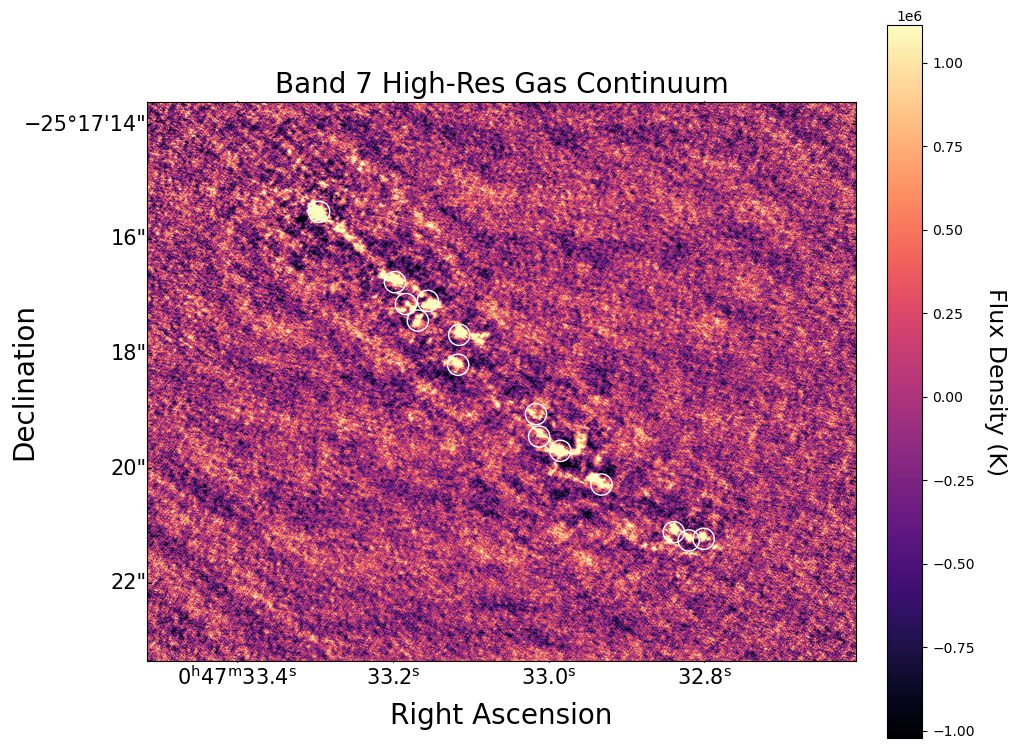

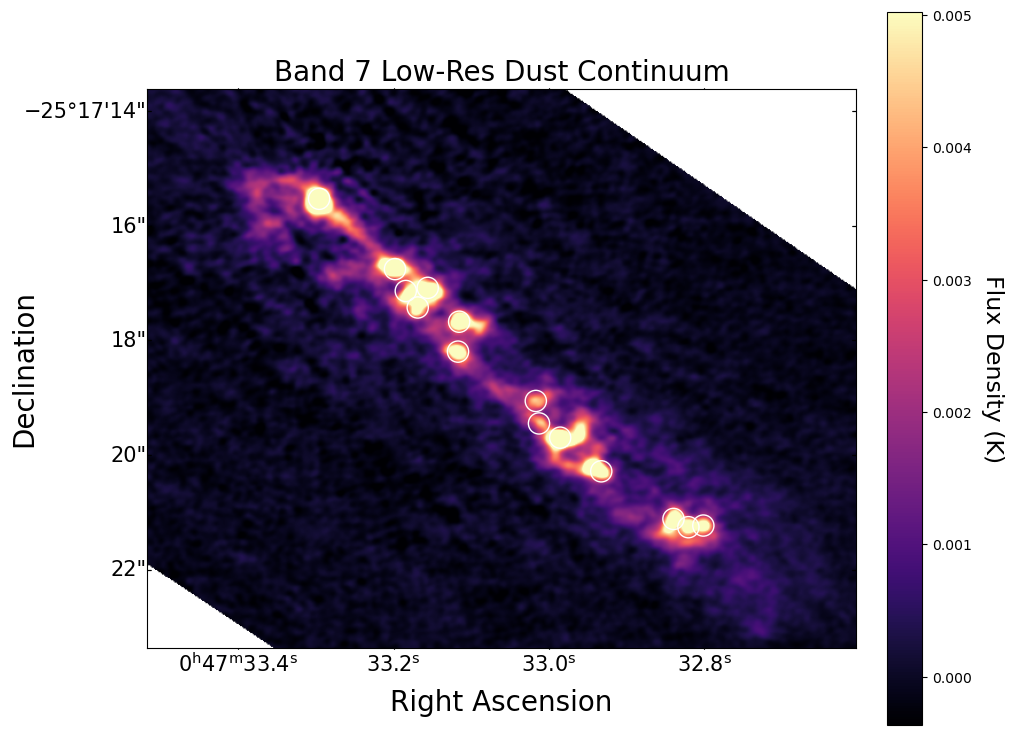

In [455]:
# Location information for arrows (if you wnat to have numbers and arrows) -- if you just want the circles, disregard
Lx  = np.array([283,273,262,222,196,184,183,139,  138,122,74,  47,102, 57])
Ly  = np.array([ 81, 80, 85, 52, 75, 85,155,205,  125,222,180, 191,235,273])
Ldx = np.array([  0,  0,  0,  0,  0,  0,  0,  0,    0,  0,  25,  50,  0,  0])
Ldy = np.array([-13,-15,-15, 20, 17, 15,-16,-20,   18, -18,  0,   0,-20,-15])
Ltx = np.array([ -5, -5, -5, -6, -6, -6, -5, -5,   -6, -10, -22, -23, -10, -10])
Lty = np.array([  3,  3,  3,-15,-15,-15,  3,  2,    -16, 2,  -6,-3,  2,  2])

#Lx  = np.array([283,273,262,222,196,184])
#Ly  = np.array([ 81, 80, 85, 52, 75, 85])
#Ldx = np.array([  0,  0,  0,  0,  0,  0])
#Ldy = np.array([-13,-15,-15, 20, 17, 15])
#Ltx = np.array([ -5, -5, -5, -6, -6, -6])
#Lty = np.array([  3,  3,  3,-15,-15,-15])

# Locations of SSCs in NGC 253
sources = np.array(['1','2','3','4','5','6','7','8','9','10','11','12','13','14'])
#sources = np.array(['1','2','3','4','5','6'])


# Plotting
data_min = np.nanpercentile(moment07h.hdu.data, 1)
data_max = np.nanpercentile(moment07h.hdu.data, 99)

fig1 = plt.figure(1,figsize=(10,20))
#ax1 = plt.subplot(1,2,1)
ax1 = plt.subplot(projection=moment07h.wcs) 
im1 = ax1.imshow(moment07h.hdu.data,cmap='magma',origin='lower',vmin=data_min,vmax=data_max)
ax1.set_title(r'Band 7 High-Res Gas Continuum', fontsize=20)

RA1 = ax1.coords[0]                                                                  
Dec1 = ax1.coords[1]
RA1.set_ticks(size=1)                                                                                      
Dec1.set_ticks(size=-3)     

plt.xlabel('Right Ascension',fontsize=20,labelpad=1)                               
plt.ylabel('Declination',fontsize=20,labelpad=0)

ax1.tick_params(axis = 'both', which = 'major', labelsize = 15)  
 
cb = fig.colorbar(im1, ax=ax1, fraction=0.046,pad=0.04)                                      
cb.set_label(label='Flux Density (K)',fontsize=17,rotation=270,labelpad=23) 
cb.ax.tick_params(which = 'major', labelsize = 10) 

for ap in apertures:
    pixel_aperture = ap.to_pixel(moment07h.wcs) # convert the CARTA RA/DEC to image pixels
    pixel_aperture.visual = {} # you need this to ignore any of the visual settings that would otherwise give you an error (i.e. symsize) as Matplotlib draws the circle
    pixel_aperture.plot(ax=ax1, edgecolor='white',linewidth=1, fill=False) # Adds the circle to our plot

#for i,x in enumerate(Lx):
#    ax1.arrow(x,Ly[i], Ldx[i], Ldy[i],width=0.1,head_width=3,head_length=3,color='black')
#    ax1.text(x+Ltx[i],Ly[i]+Lty[i],sources[i],fontsize=20,color='black')

#-----------
data_min = np.nanpercentile(moment07.hdu.data, 1)
data_max = np.nanpercentile(moment07.hdu.data, 99)

fig2 = plt.figure(2,figsize=(10,20))
#ax2 = plt.subplot(1,2,2)
ax2 = plt.subplot(projection=moment07.wcs) 
im2 = ax2.imshow(moment07.hdu.data,cmap='magma',origin='lower',vmin=data_min,vmax=data_max)

ax2.set_title(r'Band 7 Low-Res Dust Continuum', fontsize=20)

RA = ax2.coords[0]                                                                  
Dec = ax2.coords[1]
RA.set_ticks(size=1)                                                                                      
Dec.set_ticks(size=-3)     

plt.xlabel('Right Ascension',fontsize=20,labelpad=1)                               
plt.ylabel('Declination',fontsize=20,labelpad=0)

ax2.tick_params(axis = 'both', which = 'major', labelsize = 15)  
 
cb = fig.colorbar(im2, ax=ax2, fraction=0.046,pad=0.04)                                      
cb.set_label(label='Flux Density (K)',fontsize=17,rotation=270,labelpad=23) 
cb.ax.tick_params(which = 'major', labelsize = 10) 

for ap in apertures:
    pixel_aperture = ap.to_pixel(moment07.wcs) # convert the CARTA RA/DEC to image pixels
    pixel_aperture.visual = {} # you need this to ignore any of the visual settings that would otherwise give you an error (i.e. symsize) as Matplotlib draws the circle
    pixel_aperture.plot(ax=ax2, edgecolor='white',linewidth=1, fill=False) # Adds the circle to our plot

#plt.savefig('Continuum Comparisons')
########################### this is the aperture plotting that is important!! ###########################

#for ap in apertures:
#    pixel_aperture = ap.to_pixel(moment03.wcs) # convert the CARTA RA/DEC to image pixels
#    pixel_aperture.visual = {} # you need this to ignore any of the visual settings that would otherwise give you an error (i.e. symsize) as Matplotlib draws the circle
#    pixel_aperture.plot(ax=ax2, edgecolor='white',linewidth=0.7, fill=False) # Adds the circle to our plot


############################################################################################################

# Add arrows and numbers
#for i,x in enumerate(Lx):
#    ax.arrow(x,Ly[i], Ldx[i], Ldy[i],width=0.1,head_width=3,head_length=3,color='white')
#    ax.text(x+Ltx[i],Ly[i]+Lty[i],sources[i],fontsize=20,color='white')

############################################################################################################

# Add 30 pc scale bar
D = 3.5e6 * u.pc
L = 30 * u.pc
theta = (L / D) * u.rad
theta_arcsec = theta.to(u.arcsec)
#pixscale = abs(H40alpha_processed_cube.header['CDELT1']) * u.deg
pixscale = abs(crop_cont7h_cube.header['CDELT1']) * u.deg
bar_length_pix = (theta_arcsec / pixscale.to(u.arcsec)).value
ax.plot([10, 10 + bar_length_pix],[10, 10],color='white',lw=2)
ax.text(10 + bar_length_pix / 2,12,"30 pc",color='white',ha='center',va='bottom',fontsize=11)

# Add Beam
#beam_radius_pix = (H40alpha_processed_cube.header['BMAJ'] / abs(H40alpha_processed_cube.header['CDELT1'])) / 2.0
beam_radius_pix = (crop_cont7h_cube.header['BMAJ'] / abs(crop_cont7h_cube.header['CDELT1'])) / 2.0
ny, nx = moment07h.shape
beam_x = nx - 15
beam_y = 15
ax.add_patch(matplotlib.patches.Circle((beam_x, beam_y),beam_radius_pix,fill=True,lw=1.2,fc='white',ec='white')) 

plt.show()

## H40a vs. Band 3 High-Res Cont

In [ ]:
# You'll need this package
import regions
from regions import Regions
from regions import PixCoord
from regions import RectangleSkyRegion, RectanglePixelRegion

import pylab

# Load the CARTA region file
region_path = '/Users/mills-group/Downloads/regions-notebook/NGC253_H27alpha_cropped_cube.pbcor.fits'
H40a_region = Regions.read(region_path, format="crtf")
print(f"Loaded {len(H40a_crop)} aperture")

H40a_path = "/Users/mills-group/Downloads/regions-notebook/NGC253_H27alpha_cropped_cube.pbcor.fits"
H40a_cube = SpectralCube.read(H40a_path)

filelabel = "NGC253_H40a"
fmt_label = "H40 $a$"

H40a_crop = H40a_cube.subcube_from_regions(H40a_region)
H40a_crop.hdu.writeto('NGC253_H40a_2016.1.00481.c.S.fits', overwrite=True)

H40a_crop_cube = SpectralCube.read(H40a_path)

moment0 = H40a_crop_cube.moment(order=0, how='slice')
imgshape = np.shape(moment0)
print(imgshape)

In [450]:
imagename7h = 'NGC253_Band7_continuum_highres_fromH27alphadataset'
ext = '.fits'
#rest_freq3 = header['RESTFRQ']
cont7h_fake = fake_cube(imagename7h, ext)
cont7h_cube_path = '/Users/mills-group/Downloads/Band7H27a/NGC253_Band7_continuum_highres_fromH27alphadataset.fits'
image7h = fits.getdata(cont7h_cube_path)
header7h = fits.getheader(cont7h_cube_path)
w7 = WCS(header7h)
w7 = w7.dropaxis(2)
crop_region_cont7_path = "/Users/mills-group/Downloads/Band7H27a/band7region"
#region = regions.Regions.parse(crop_region_cont7_path,format='crtf')
print(np.shape(image7h))

cont7h_region = Regions.read(crop_region_cont7_path, format='crtf')
image7h = pylab.squeeze(image7h)
print(np.shape(image7h))
cont7h_cube = SpectralCube.read(cont7h_cube_path)
print(np.shape(image7h))


#region = regions.Regions.parse(region_str,format='crtf')
crop_cont7h_cube = cont7h_cube.subcube_from_regions(cont7h_region)

moment07h = crop_cont7h_cube.moment(order=0, how='slice')
#-------------


(1, 1, 2352, 2352)
(2352, 2352)


(2352, 2352)
(1500, 2500)
(1500, 2500)
